<a href="https://colab.research.google.com/github/maramgueye/portfolio_construction_theory/blob/main/lecture6_parameter_estimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import statsmodels.api as sm
from scipy.optimize import minimize

In [2]:
plt.rcParams.update({'axes.grid': True})

# Data Preparation (*)

## Importing the Data (*)

In [3]:
try :
  from google.colab import files
  uploaded = files.upload()
except ImportError:
  pass

Saving stocks.csv to stocks.csv


In [4]:
ret = pd.read_csv('stocks.csv',
                  parse_dates=['date'],
                  index_col='date')

## Making Weekly and Monthly Datasets (*)

In [5]:
val = (1. + ret).cumprod()
val_d = val.reindex(pd.date_range(val.index[0], val.index[-1])).ffill()

In [6]:
val_w = val_d.resample('W-FRI').last()  # Values on Fridays
ret_w = val_w.pct_change().iloc[1:, :]  # Weekly returns (drop first row)

In [7]:
val_m = val_d.resample('MS').last()  # Values at month start
ret_m = val_m.pct_change().iloc[1:, :]  # Monthly returns (drop first row)

# The Sample Mean Returns

Our dataset consists of daily returns on the 10 US stocks from January 2023 to December 2024.

In [8]:
ret

,AAPL,AMZN,BA,BAC,F,IBM,JPM,MSFT,V,WMT
date,,,,,,,,,,
2023-01-03,-0.037405,0.021667,0.025723,0.011775,0.004299,0.004685,0.007606,-0.001001,-0.001781,0.012765
2023-01-04,0.010314,-0.007924,0.042223,0.018800,0.028253,0.007418,0.009325,-0.043743,0.025170,0.001114
2023-01-05,-0.010605,-0.023726,0.006629,-0.002050,0.019983,-0.010449,-0.000220,-0.029638,-0.007055,-0.003408
2023-01-06,0.036794,0.035611,0.039075,0.009979,0.026939,0.018354,0.019136,0.011785,0.031453,0.024499
2023-01-09,0.004089,0.014870,-0.020798,-0.015112,0.008744,-0.001044,-0.004132,0.009736,0.003904,-0.012468
...,...,...,...,...,...,...,...,...,...,...
2024-12-24,0.011478,0.017729,0.009286,0.011164,0.012121,0.011175,0.016444,0.009374,0.010813,0.025789
2024-12-26,0.003176,-0.008732,0.005799,0.003831,0.004990,0.002139,0.003425,-0.002777,0.000811,0.001187
2024-12-27,-0.013242,-0.014534,0.001885,-0.004714,-0.003972,-0.009382,-0.008102,-0.017302,-0.007011,-0.012178


In [9]:
mean_ret = ret.mean()

mean_ret_ann = mean_ret * 252  # Annualized sample means

## Exercise: Calculating Confidence Bounds

# The Sample Covariance Matrix

The sample covariance matrix is obtained with the DataFrame method `cov`:

In [10]:
mean_ret=ret.mean()

In [11]:
sample_cov = ret.cov()
sample_cov

,AAPL,AMZN,BA,BAC,F,IBM,JPM,MSFT,V,WMT
AAPL,0.000184,0.000099,0.000057,0.000030,0.000052,0.000024,0.000025,0.000097,0.000041,0.000015
AMZN,0.000099,0.000372,0.000083,0.000055,0.000080,0.000042,0.000048,0.000171,0.000055,0.000040
BA,0.000057,0.000083,0.000381,0.000079,0.000098,0.000028,0.000060,0.000030,0.000030,0.000025
BAC,0.000030,0.000055,0.000079,0.000245,0.000166,0.000067,0.000158,0.000029,0.000053,0.000021
F,0.000052,0.000080,0.000098,0.000166,0.000503,0.000056,0.000120,0.000062,0.000068,0.000035
IBM,0.000024,0.000042,0.000028,0.000067,0.000056,0.000158,0.000057,0.000033,0.000033,0.000028
JPM,0.000025,0.000048,0.000060,0.000158,0.000120,0.000057,0.000195,0.000024,0.000057,0.000016
MSFT,0.000097,0.000171,0.000030,0.000029,0.000062,0.000033,0.000024,0.000204,0.000046,0.000021
V,0.000041,0.000055,0.000030,0.000053,0.000068,0.000033,0.000057,0.000046,0.000104,0.000021
WMT,0.000015,0.000040,0.000025,0.000021,0.000035,0.000028,0.000016,0.000021,0.000021,0.000111


In [12]:
sample_vol=ret.std()
T=len(ret)
lb=mean_ret-sample_vol/np.sqrt(T)
ub=mean_ret+sample_vol/np.sqrt(T)

In [13]:
lb_ann=lb*252
mean_ret_ann
ub_ann=ub*252

In [14]:
pd.DataFrame({'lb_ann':lb_ann,
              'mean_ret_ann':mean_ret_ann,
              'ub_ann':ub_ann})

,lb_ann,mean_ret_ann,ub_ann
AAPL,0.205457,0.357859,0.510260
AMZN,0.312125,0.529089,0.746052
BA,-0.208226,0.011288,0.230802
BAC,0.024655,0.200782,0.376909
F,-0.184593,0.067639,0.319871
IBM,0.144237,0.285610,0.426983
JPM,0.185732,0.342638,0.499543
MSFT,0.156482,0.316997,0.477513
V,0.116708,0.231626,0.346543
WMT,0.234427,0.353033,0.471638


We have such wide confidence bound, so we have very inaccurate estimate of expected return.

# Introducing Weight Constraints

Let us annualize the covariance matrix by multiplying the daily matrix by 252.

In [15]:
sample_cov_ann = ret.cov() * 252

Note that, because we are using simple returns, this annualization method is not fully rigorous (the correct annualization formula is more complicated), but it has the merit of simplicity and allows us to quickly convert daily average returns and daily volatilities into annual numbers, which are more easily interpretable.

The "plug-in" GMV portfolio is obtained by using the sample estimate for $\mathbf{\Sigma}$:

In [16]:
e = np.ones(len(ret.columns))  # Vector of 1
x = np.linalg.solve(sample_cov_ann, e)
gmv = x / x.sum()
gmv

array([ 0.11629623, -0.05591957,  0.05403034,  0.0077102 , -0.02468514,
        0.13763976,  0.09073811,  0.10911691,  0.24204104,  0.32303211])

To calculate expected excess returns, we assume a risk-free interest rate of 2% per year.

In [17]:
rf = .02

The estimated tangency portfolio is given by

In [18]:
x = np.linalg.inv(sample_cov_ann) @ (mean_ret_ann - rf)
tan = x / x.sum()
tan

array([ 0.24422461,  0.14720007, -0.11717939, -0.13198401, -0.09836863,
        0.12748768,  0.35290423, -0.02674764,  0.04695757,  0.4555055 ])

Both the GMV and the tangency portfolios contain short positions.

To do numerical optimization, we need a function that returns the variance (that we will minimize) and one that returns the Sharpe ratio (that we will maximize).

In [19]:
def variance(w):
    return w @ sample_cov_ann @ w


def sharpe_ratio(w):
    return w @ (mean_ret_ann - rf) / np.sqrt(w @ sample_cov_ann @ w)

We will use the equally weighted portfolio of all stocks as the start point for optimization.

In [20]:
N = len(ret.columns)  # Number of assets
e = np.ones(N)  # Vector of 1
w0 = e / N  # Initial guess: Equally-weighted portfolio

bud_cons = {'type': 'eq',  # Equality constraint
           'fun': lambda w: w.sum() - 1.,  # Must be 0
           }

We first verify that we recover the composition of the long-short GMV portfolio if there are no bounds on weights:

In [21]:
res_gmv_ls = minimize(variance, # Objective function to minimize
                      w0,
                      constraints=[bud_cons]
                      )

res_gmv_ls

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.01228250716858952
           x: [ 1.171e-01 -5.533e-02  5.404e-02  8.497e-03 -2.595e-02
                1.381e-01  9.024e-02  1.076e-01  2.404e-01  3.254e-01]
         nit: 15
         jac: [ 2.455e-02  2.455e-02  2.455e-02  2.452e-02  2.427e-02
                2.458e-02  2.449e-02  2.445e-02  2.447e-02  2.467e-02]
        nfev: 165
        njev: 15
 multipliers: [ 2.457e-02]

In [22]:
res_gmv_ls.x - gmv

array([ 7.66184674e-04,  5.88627989e-04,  1.28707512e-05,  7.86659148e-04,
       -1.26868538e-03,  4.24372727e-04, -4.99555114e-04, -1.54312147e-03,
       -1.61997631e-03,  2.35262298e-03])

In [23]:
np.abs(res_gmv_ls.x - gmv).max()

np.float64(0.002352622981746433)

The result is close to the GMV portfolio given by the matrix formula, since the biggest absolute difference is only 0.2 percentage points.

We now introduce the long-only constraints. For each asset, the lower bound is 0, and no lower bound is imposed, so the upper bound is set to `None` in the code below.

In [24]:
bounds = [(0., None)] * N  # One pair of bounds for every asset

res_gmv_lo = minimize(variance,
                      w0,
                      constraints=[bud_cons],  # Constraints other than bounds
                      bounds=bounds  # Bounds
                      )

res_gmv_lo

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.012511722246204986
           x: [ 1.141e-01  8.206e-18  4.395e-02  3.404e-05  0.000e+00
                1.395e-01  8.279e-02  6.403e-02  2.346e-01  3.210e-01]
         nit: 12
         jac: [ 2.494e-02  3.102e-02  2.479e-02  2.535e-02  2.976e-02
                2.505e-02  2.499e-02  2.489e-02  2.491e-02  2.520e-02]
        nfev: 132
        njev: 12
 multipliers: [ 2.502e-02]

In [25]:
gmv_lo = res_gmv_lo.x

Let us collect the weights of the long-short and the long-only GMV portfolios in a DataFrame and plot them.

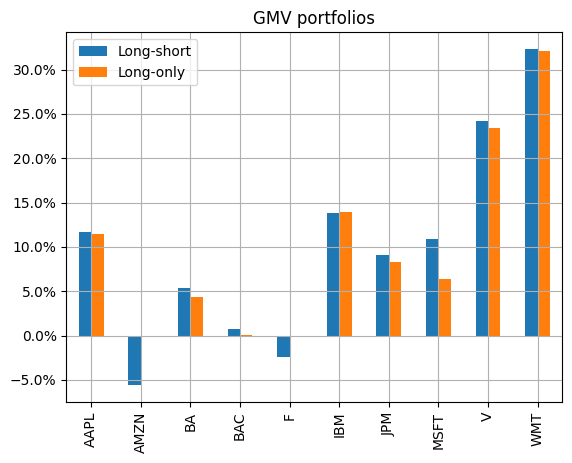

In [26]:
gmv_all = pd.DataFrame({'Long-short': gmv,
                        'Long-only': gmv_lo},
                        index=ret.columns)

ax = gmv_all.plot.bar(title='GMV portfolios')
ax.yaxis.set_major_formatter(PercentFormatter(1.))
plt.savefig('gmv.pdf')

The stocks that had negative weights in the long-short portfolio are excluded from the long-only one.

We proceed in a similar way for the tangency portfolio.

In [ ]:
res_tan_ls = minimize(lambda w: -sharpe_ratio(w), # Objective to minimize
                      w0,
                      constraints=[bud_cons]
                      )

res_tan_ls

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -3.0656975868106695
           x: [ 2.443e-01  1.472e-01 -1.172e-01 -1.320e-01 -9.835e-02
                1.275e-01  3.530e-01 -2.689e-02  4.711e-02  4.554e-01]
         nit: 12
         jac: [-5.225e-04  1.179e-03 -6.859e-04 -1.484e-03 -1.260e-03
               -3.068e-04 -1.415e-03  7.174e-04 -7.561e-04  3.209e-04]
        nfev: 146
        njev: 12
 multipliers: [ 6.920e-05]

In [ ]:
tan

array([ 0.24422461,  0.14720007, -0.11717939, -0.13198401, -0.09836863,
        0.12748768,  0.35290423, -0.02674764,  0.04695757,  0.4555055 ])

We then proceed to introducing the weight constraints.

In [ ]:
res_tan_lo = minimize(lambda w: -sharpe_ratio(w), # Objective to minimize
                      w0,
                      constraints=[bud_cons],  # Constraints other than bounds
                      bounds=bounds  # Bounds
                      )

res_tan_lo

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -2.778340589128094
           x: [ 1.929e-01  1.098e-01  7.818e-16  0.000e+00  2.491e-15
                9.791e-02  1.732e-01  0.000e+00  1.586e-02  4.104e-01]
         nit: 11
         jac: [ 6.130e-04 -1.739e-03  2.101e+00  1.063e+00  2.396e+00
                3.171e-04 -2.392e-04  7.767e-02  8.382e-04  1.699e-04]
        nfev: 125
        njev: 11
 multipliers: [-2.473e-05]

In [ ]:
tan_lo = res_tan_lo.x

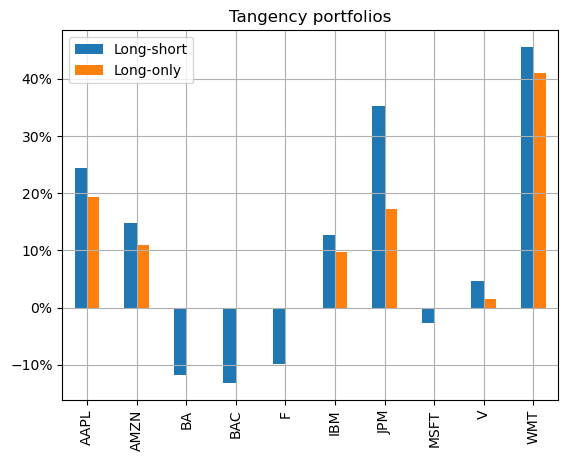

In [ ]:
tan_all = pd.DataFrame({'Long-short': tan,
                        'Long-only': tan_lo},
                        index=ret.columns)

ax = tan_all.plot.bar(title='Tangency portfolios')
ax.yaxis.set_major_formatter(PercentFormatter(1.))
plt.savefig('tan.pdf')

Both long-only portfolios assign zero weights to some assets.

### Exercice : calculate the average of the off-diagonale element

In [ ]:
C=ret.corr()

In [39]:
N= len(C)
def ave_off_diagonale (ret):
  sum=0
  for i in range (N):
    for j in range(N):
      if j<i: #car cor(i,j)=cor(j,i)
        sum=sum+j
  return sum/N

ave_off_diagonale(C)
#doit-on diviser par 2 puisque cor(i,j)=cor(j,i)

12.0

In [36]:
C.sum().sum()

np.float64(31.8239304518344)

In [37]:
C

,AAPL,AMZN,BA,BAC,F,IBM,JPM,MSFT,V,WMT
AAPL,1.000000,0.378730,0.216708,0.139204,0.169683,0.142990,0.130905,0.502076,0.297757,0.101840
AMZN,0.378730,1.000000,0.220818,0.183112,0.185292,0.174243,0.180199,0.620350,0.280052,0.196071
BA,0.216708,0.220818,1.000000,0.257297,0.224767,0.115186,0.220299,0.108574,0.148383,0.122885
BAC,0.139204,0.183112,0.257297,1.000000,0.471710,0.339025,0.723415,0.130614,0.334298,0.125418
F,0.169683,0.185292,0.224767,0.471710,1.000000,0.198345,0.385031,0.192562,0.294995,0.148384
IBM,0.142990,0.174243,0.115186,0.339025,0.198345,1.000000,0.324293,0.182186,0.255904,0.214419
JPM,0.130905,0.180199,0.220299,0.723415,0.385031,0.324293,1.000000,0.118438,0.400828,0.109406
MSFT,0.502076,0.620350,0.108574,0.130614,0.192562,0.182186,0.118438,1.000000,0.313109,0.138768
V,0.297757,0.280052,0.148383,0.334298,0.294995,0.255904,0.400828,0.313109,1.000000,0.193396
WMT,0.101840,0.196071,0.122885,0.125418,0.148384,0.214419,0.109406,0.138768,0.193396,1.000000


## Exercise: Calculating the Opportunity Cost of Long-Only Constraints